# Task design figure

Draws `figures/00_design.png`: (A) chord set, (B) session structure, (C) trial structure.

Block layout comes from `utils/design.py`; fixed trial timings from the target files; execution time is the median go-cue-to-chord time (RT + ET) on correct trials of the 4-day subjects.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Ellipse, FancyArrowPatch, Rectangle

# project root = the folder that contains target/ and data/
ROOT = Path.cwd()
while not (ROOT / "target").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from utils.design import LAST_BLOCK, SEGMENTS

SUBJECTS = [101, 102, 103, 104]   # full 4-day design; s100 was the 3-day pilot
TRIALS_PER_BLOCK = 20

In [2]:
# ----------------------------------------------------------------- trial timing
# Fixed parameters come from the target files, execution time from the data:
# go cue -> chord reached (RT + ET) on correct trials, all blocks of SUBJECTS.
tgt = pd.concat([pd.read_csv(f, sep="\t")
                 for sn in SUBJECTS for f in sorted((ROOT / "target").glob(f"s{sn}_*.tgt"))])
plan_lo, plan_hi = tgt.planTime.min(), tgt.planTime.max()
hold = int(tgt.success_holdTime.iloc[0])
exec_max = int(tgt.execMaxTime.iloc[0])
feedback = int(tgt.feedbackTime.iloc[0])
iti = int(tgt.iti.iloc[0])
for col in ["success_holdTime", "execMaxTime", "feedbackTime", "iti"]:
    assert tgt[col].nunique() == 1, f"{col} varies across target files"

pilot_tgt = pd.concat([pd.read_csv(f, sep="\t") for f in sorted((ROOT / "target").glob("s100_*.tgt"))])
pilot_feedback = int(pilot_tgt.feedbackTime.iloc[0])

beh = pd.concat([pd.read_csv(ROOT / "analysis" / f"s{sn}.csv") for sn in SUBJECTS])
ok = beh[beh.trialPoint == 1]
reach = float(np.median(ok.RT + ok.ET))
plan_mid = (plan_lo + plan_hi) / 2
trial_typ = plan_mid + reach + hold + feedback + iti
print(f"planning {plan_lo}-{plan_hi} ms, reach median {reach:.0f} ms, hold {hold}, "
      f"feedback {feedback} (pilot {pilot_feedback}), ITI {iti}, typical trial {trial_typ/1000:.1f} s")

planning 1100-1399 ms, reach median 1064 ms, hold 600, feedback 1000 (pilot 500), ITI 500, typical trial 4.4 s


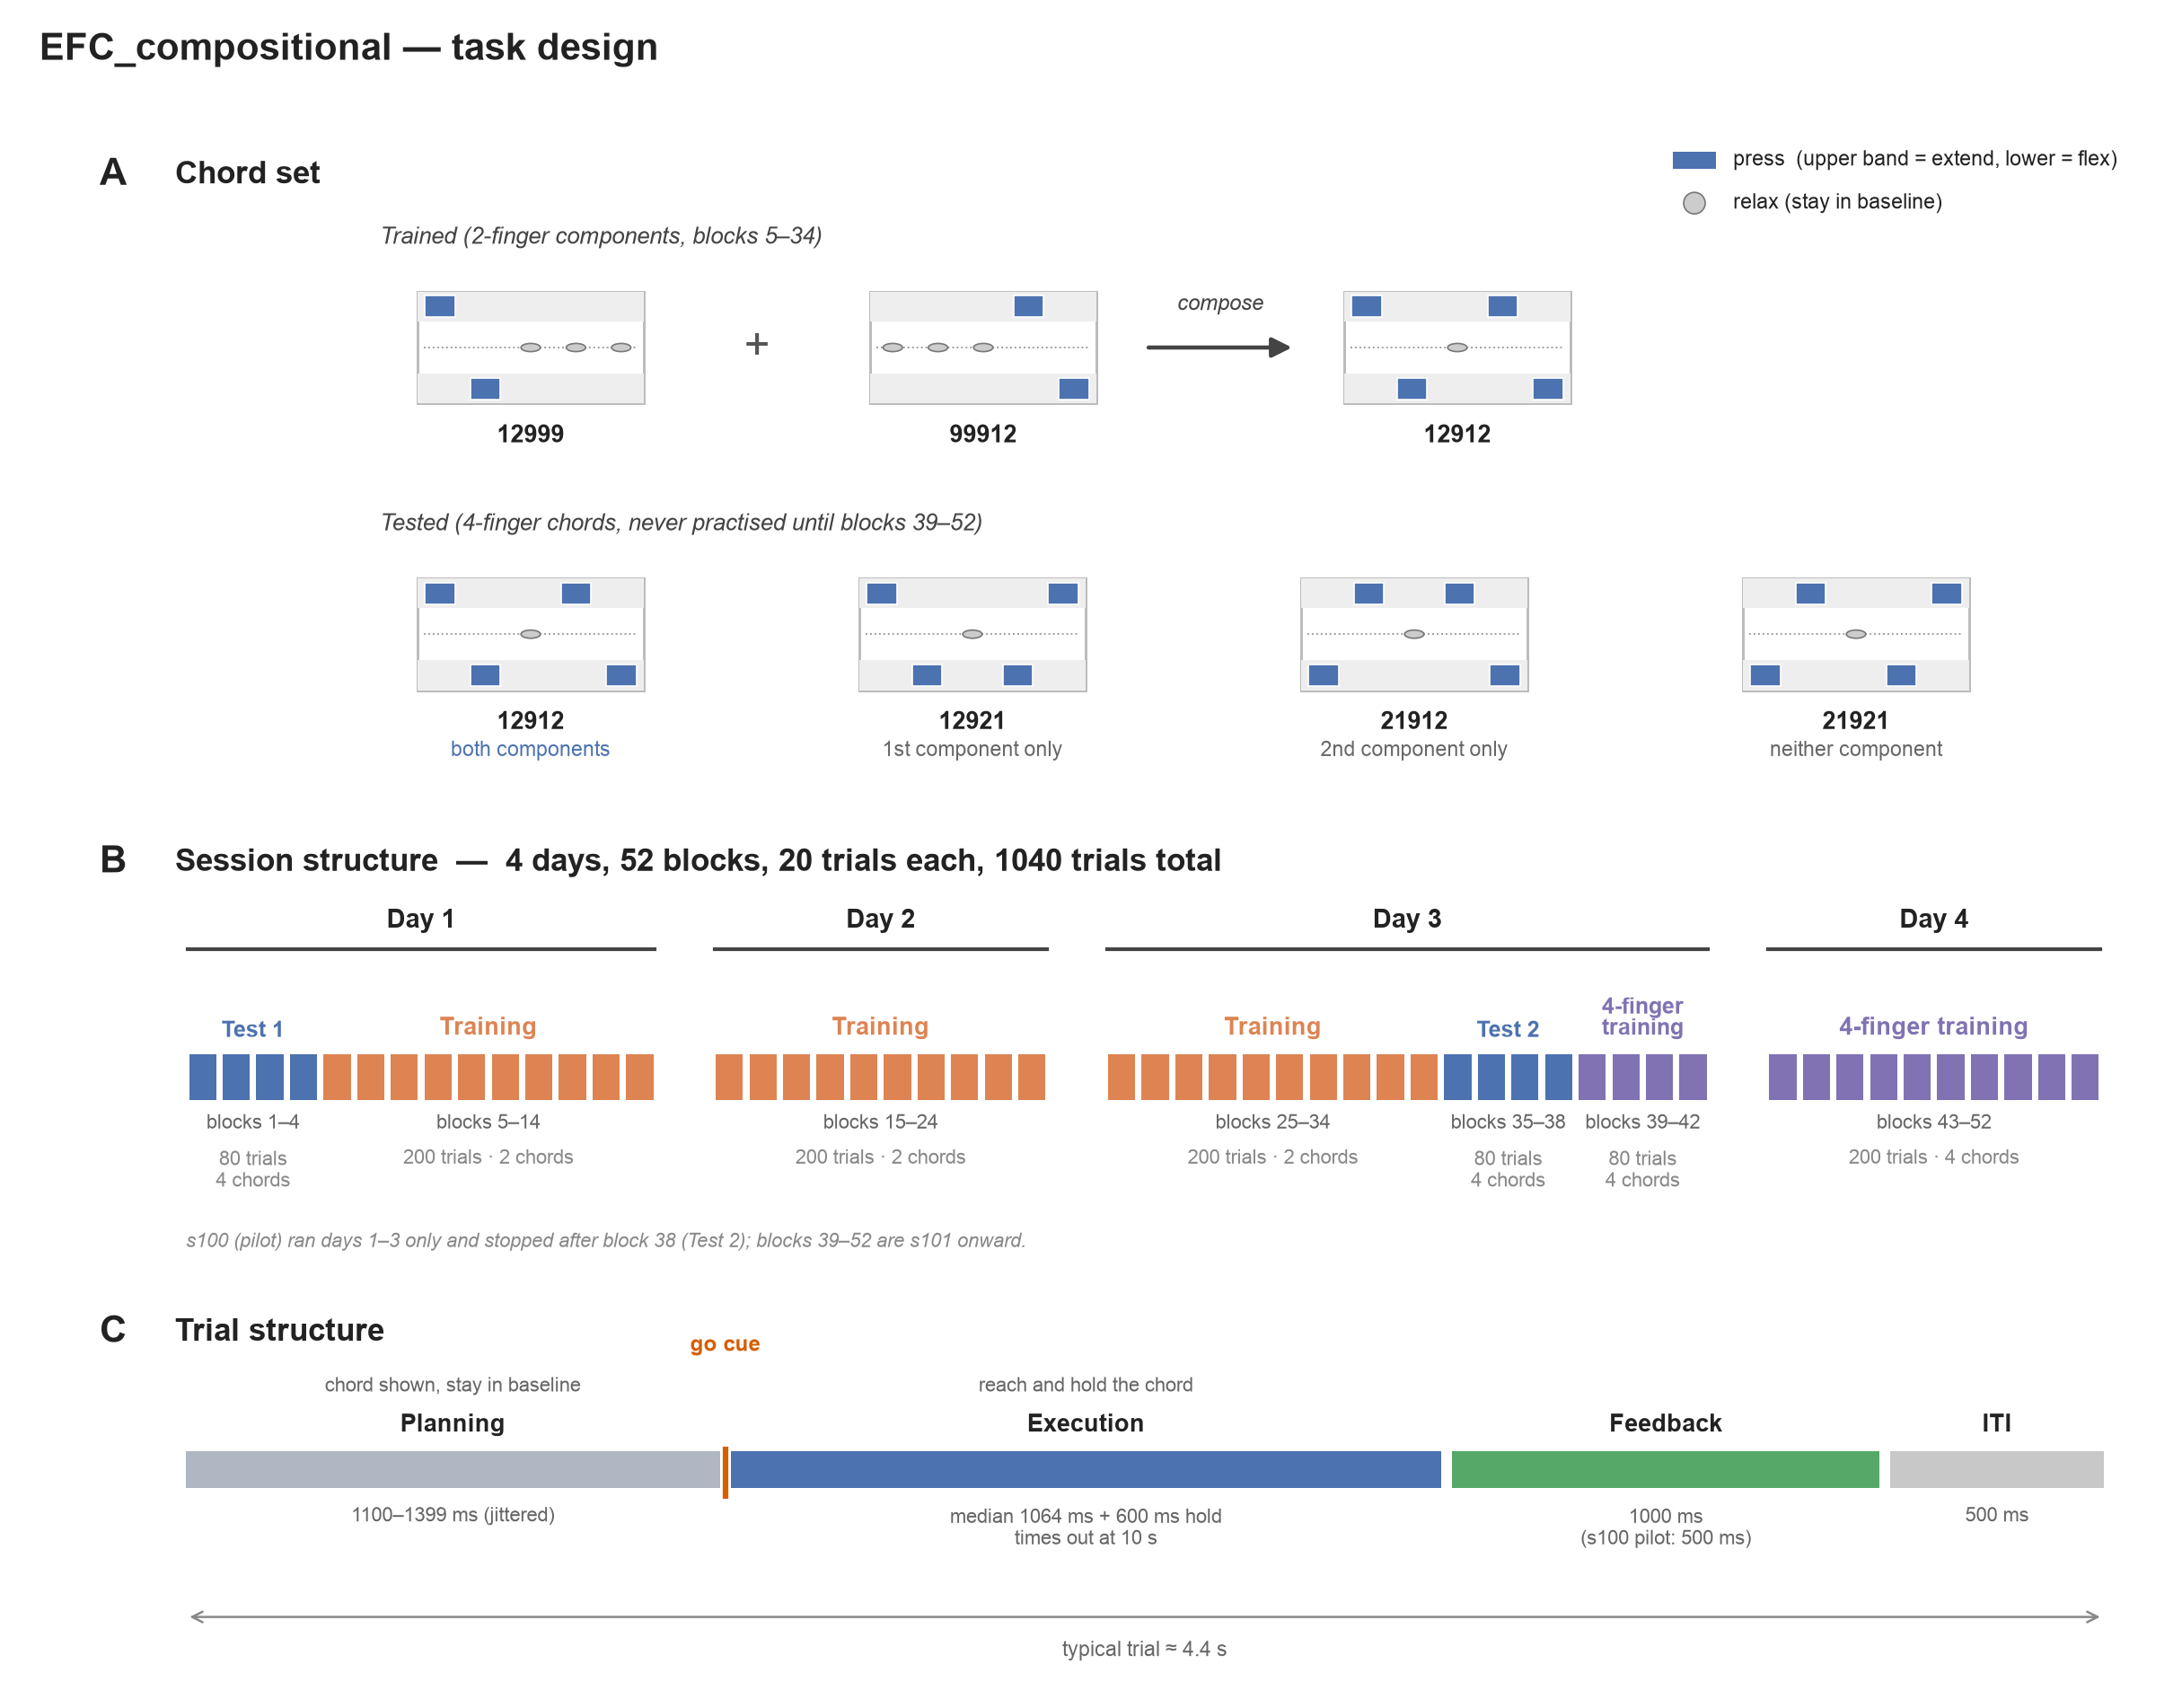

In [3]:
# ----------------------------------------------------------------- style
C_TEST = "#4C72B0"     # 4-finger chords, tested
C_TRAIN = "#DD8452"    # 2-finger component training
C_4FTRAIN = "#8172B3"  # 4-finger chords, practised
C_PRESS = "#4C72B0"
C_TEXT = "#222222"
C_SUB = "#666666"
SEG_COLOR = {"Test 1": C_TEST, "Test 2": C_TEST, "Training": C_TRAIN, "4-finger training": C_4FTRAIN}

plt.rcParams.update({"font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"]})

# one canvas in square data units: x 0..100, y 0..78
fig = plt.figure(figsize=(16, 12.48), dpi=150)
ax = fig.add_axes([0, 0, 1, 1])
ax.set_xlim(0, 100)
ax.set_ylim(0, 78)
ax.axis("off")


def text(x, y, s, size=11, color=C_TEXT, weight="normal", ha="center", va="center", style="normal", **kw):
    ax.text(x, y, s, fontsize=size, color=color, fontweight=weight, ha=ha, va=va, fontstyle=style, **kw)


def panel(x, y, letter, title):
    text(x, y, letter, size=20, weight="bold", ha="left")
    text(x + 3.5, y, title, size=17, weight="bold", ha="left")


def chord(cx, cy, code, w=10.5, h=5.2):
    """Draw a chord glyph: upper band = extend (1), lower band = flex (2), 9 = relax."""
    x0, y0 = cx - w / 2, cy - h / 2
    band = 1.4
    ax.add_patch(Rectangle((x0, y0), w, h, facecolor="white", edgecolor="#BBBBBB", lw=1.4, zorder=1))
    ax.add_patch(Rectangle((x0, y0 + h - band), w, band, facecolor="#EEEEEE", edgecolor="none", zorder=1))
    ax.add_patch(Rectangle((x0, y0), w, band, facecolor="#EEEEEE", edgecolor="none", zorder=1))
    ax.plot([x0 + 0.3, x0 + w - 0.3], [cy, cy], ls=":", color="#999999", lw=0.9, zorder=2)
    for i, d in enumerate(code):
        fx = x0 + (i + 0.5) * w / 5
        if d == "9":
            ax.add_patch(Ellipse((fx, cy), 0.9, 0.38, facecolor="#CCCCCC", edgecolor="#777777", lw=0.8, zorder=3))
        else:
            fy = y0 + h - band / 2 if d == "1" else y0 + band / 2
            ax.add_patch(Rectangle((fx - 0.7, fy - 0.5), 1.4, 1.0, facecolor=C_PRESS, edgecolor="white", lw=0.8, zorder=3))
    text(cx, y0 - 1.5, code, size=13, weight="bold")


# ----------------------------------------------------------------- header
text(1.2, 76.3, "EFC_compositional — task design", size=20, weight="bold", ha="left")

# ----------------------------------------------------------------- A: chord set
panel(4, 70.5, "A", "Chord set")

# legend
lx, ly = 77, 71.2
ax.add_patch(Rectangle((lx, ly - 0.4), 2.0, 0.8, facecolor=C_PRESS, edgecolor="none"))
text(lx + 2.8, ly, "press  (upper band = extend, lower = flex)", size=11, ha="left")
ax.add_patch(Ellipse((lx + 1.0, ly - 2.0), 1.0, 1.0, facecolor="#CCCCCC", edgecolor="#777777", lw=0.8))
text(lx + 2.8, ly - 2.0, "relax (stay in baseline)", size=11, ha="left")

text(17, 67.6, "Trained (2-finger components, blocks 5–34)", size=12.5, color="#444444", ha="left", style="italic")
row1 = 62.5
chord(24, row1, "12999")
text(34.5, row1, "+", size=24, color="#555555")
chord(45, row1, "99912")
ax.add_patch(FancyArrowPatch((52.5, row1), (59.5, row1), arrowstyle="-|>", mutation_scale=22, lw=2.2, color="#444444"))
text(56, row1 + 2.0, "compose", size=11.5, color="#444444", style="italic")
chord(67, row1, "12912")

text(17, 54.3, "Tested (4-finger chords, never practised until blocks 39–52)",
     size=12.5, color="#444444", ha="left", style="italic")
row2 = 49.2
tested = [("12912", "both components", C_TEST), ("12921", "1st component only", C_SUB),
          ("21912", "2nd component only", C_SUB), ("21921", "neither component", C_SUB)]
for i, (code, label, col) in enumerate(tested):
    cx = 24 + i * 20.5
    chord(cx, row2, code)
    text(cx, row2 - 5.4, label, size=11, color=col)

# ----------------------------------------------------------------- B: session structure
n_blocks = sum(len(s["blocks"]) for s in SEGMENTS)
n_days = max(s["day"] for s in SEGMENTS)
panel(4, 38.6, "B", f"Session structure  —  {n_days} days, {n_blocks} blocks, "
                    f"{TRIALS_PER_BLOCK} trials each, {n_blocks * TRIALS_PER_BLOCK} trials total")

slot, bw, day_gap = 1.56, 1.26, 2.6
x_start = 8.0
y_blk, h_blk = 27.6, 2.1
x = x_start
day_span = {}
for seg in SEGMENTS:
    if day_span and seg["day"] not in day_span:
        x += day_gap
    seg_x0 = x
    for b in seg["blocks"]:
        ax.add_patch(Rectangle((x + (slot - bw) / 2, y_blk), bw, h_blk, facecolor=SEG_COLOR[seg["name"]],
                               edgecolor="none"))
        x += slot
    seg_x1 = x
    lo, hi = day_span.get(seg["day"], (seg_x0, seg_x1))
    day_span[seg["day"]] = (min(lo, seg_x0), max(hi, seg_x1))

    mid = (seg_x0 + seg_x1) / 2
    narrow = len(seg["blocks"]) <= 4
    name = seg["name"].replace(" training", "\ntraining") if narrow else seg["name"]
    text(mid, y_blk + h_blk + 0.7, name, size=12 if narrow else 13, weight="bold",
         color=SEG_COLOR[seg["name"]], va="bottom", linespacing=1.0)
    n_chords = 2 if seg["kind"] == "2f" else 4
    text(mid, y_blk - 1.1, f"blocks {min(seg['blocks'])}–{max(seg['blocks'])}", size=10.5, color=C_SUB)
    trials = f"{len(seg['blocks']) * TRIALS_PER_BLOCK} trials"
    detail = f"{trials}\n{n_chords} chords" if narrow else f"{trials} · {n_chords} chords"
    text(mid, y_blk - 2.3, detail, size=10.5, color="#888888", va="top")

for d, (x0, x1) in day_span.items():
    y = 34.6
    ax.plot([x0 + 0.1, x1 - 0.1], [y, y], color="#444444", lw=2)
    text((x0 + x1) / 2, y + 1.3, f"Day {d}", size=14, weight="bold")

pilot_last = LAST_BLOCK[100]
text(x_start, 21.0, f"s100 (pilot) ran days 1–3 only and stopped after block {pilot_last} (Test 2); "
                    f"blocks {pilot_last + 1}–{n_blocks} are s101 onward.",
     size=10.5, color="#888888", ha="left", style="italic")

# ----------------------------------------------------------------- C: trial structure
panel(4, 16.8, "C", "Trial structure")
phases = [
    ("Planning", plan_mid, "#B0B7C3", "chord shown, stay in baseline", f"{plan_lo}–{plan_hi} ms (jittered)"),
    ("Execution", reach + hold, C_TEST, "reach and hold the chord",
     f"median {reach:.0f} ms + {hold} ms hold\ntimes out at {exec_max // 1000} s"),
    ("Feedback", feedback, "#55A868", "", f"{feedback} ms\n(s100 pilot: {pilot_feedback} ms)"),
    ("ITI", iti, "#C8C8C8", "", f"{iti} ms"),
]
cx0, cx1, gap = 8.0, 97.0, 0.5
scale = (cx1 - cx0 - gap * (len(phases) - 1)) / sum(p[1] for p in phases)
y_bar, h_bar = 9.6, 1.7
x = cx0
for i, (name, dur, col, above, below) in enumerate(phases):
    w = dur * scale
    ax.add_patch(Rectangle((x, y_bar), w, h_bar, facecolor=col, edgecolor="none"))
    text(x + w / 2, y_bar + h_bar + 1.2, name, size=13, weight="bold")
    if above:
        text(x + w / 2, y_bar + h_bar + 3.0, above, size=10.5, color=C_SUB)
    text(x + w / 2, y_bar - 0.9, below, size=10.5, color=C_SUB, va="top")
    if name == "Execution":  # go cue at the start of execution
        ax.plot([x - gap / 2] * 2, [y_bar - 0.5, y_bar + h_bar + 0.2], color="#D55E00", lw=3, solid_capstyle="butt")
        text(x - gap / 2, y_bar + h_bar + 4.9, "go cue", size=11.5, weight="bold", color="#D55E00")
    x += w + gap

ax.add_patch(FancyArrowPatch((cx0, 3.6), (cx1, 3.6), arrowstyle="<->", mutation_scale=14, lw=1.2, color="#888888"))
text((cx0 + cx1) / 2, 2.5, f"typical trial ≈ {trial_typ / 1000:.1f} s", size=11, color=C_SUB, va="top")

fig.savefig(ROOT / "figures" / "00_design.png", dpi=150, facecolor="white")
plt.show()